# Molecular Fingerprints and Multitask Molecular Prediction

Prof. Victor S. Batista

**CHEM 584: Introduction to Machine Learning and Quantum Computing**


**Beginner tutorial + graded assignment (100 points)**  
Source topic preserved: the original DeepChem lesson on **ECFP fingerprints**, **Tox21**, **12 toxicity assays**, masked missing labels, and a **multitask neural network**.

**Important dataset distinction:** The supplied CSV is an *illustrative teaching dataset*. Its two labels are computed from RDKit descriptors; **they are not experimental toxicity outcomes**. The optional later section uses the genuine Tox21 dataset through DeepChem. Never report the illustrative exercise as measured toxicity prediction.

### Learning objectives
Translate SMILES into fingerprints; explain hashing and collisions; understand feature arrays and labels; split data correctly; recognize missing labels through masks; compare a simple baseline with a multi-output neural network; describe ROC–AUC and its limitations.

**To submit:** An executed `.ipynb` containing completed TODO cells, figures, numerical results, and written responses. Record package versions and random seed.

## Part 1 — Why turn molecules into numbers?
A machine-learning model generally requires a fixed-size numerical input. **SMILES** records a molecular graph as text, but two strings can encode the same molecule. RDKit parses a SMILES into atoms and bonds.

**Descriptor**: a measured or computed numeric property such as molecular weight. **Fingerprint**: a binary vector summarizing whether hashed local structural environments are present. A fingerprint is *not* a unique chemical identity; different environments may collide on a bit.

**Conceptual checkpoint:** What would happen if we supplied raw SMILES strings directly to a model expecting a numeric matrix? Why might a fixed 1,024-bit representation be useful?

In [ ]:
# Standard Colab-compatible imports; RDKit is preinstalled in many Colab runtimes.
import importlib.util, subprocess, sys
if importlib.util.find_spec('rdkit') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'rdkit'])
import io, os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, Descriptors, rdFingerprintGenerator, DataStructs
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve
from sklearn.dummy import DummyClassifier
from sklearn.neural_network import MLPClassifier
import sklearn
SEED=32
np.random.seed(SEED)
print('RDKit:',rdBase.rdkitVersion,'scikit-learn:',sklearn.__version__)


RDKit: 2026.09.1 scikit-learn: 1.6.1


## Part 2 — Load an external CSV (automatically prompts in Colab)

In [ ]:
# CSV is intentionally external. In Colab, an upload dialog appears if not found.
CSV_NAME='molecular_fingerprints_demo.csv'
search_paths=[Path(CSV_NAME),Path('/content')/CSV_NAME,Path('/mnt/data')/CSV_NAME]
csv_path=next((p for p in search_paths if p.is_file()),None)
if csv_path is None:
    try:
        from google.colab import files
        print('Upload molecular_fingerprints_demo.csv')
        uploaded=files.upload()
        csv_path=Path(CSV_NAME) if CSV_NAME in uploaded else None
    except ImportError:
        pass
if csv_path is None or not csv_path.is_file():
    raise FileNotFoundError(f'Missing {CSV_NAME}; upload it next to the notebook.')
raw=pd.read_csv(csv_path)
required={'smiles','demo_task_lipophilic','demo_task_hbond'}
if not required.issubset(raw.columns):raise ValueError('Missing columns: '+str(required-set(raw.columns)))
if raw['smiles'].isna().any() or raw['smiles'].duplicated().any():raise ValueError('SMILES missing or duplicated')
if not raw.smiles.map(lambda s:Chem.MolFromSmiles(str(s)) is not None).all():raise ValueError('Invalid SMILES')
for col in sorted(required-{'smiles'}):
    vals=set(raw[col].dropna().unique().tolist())
    if not vals.issubset({0,1,0.0,1.0}):raise ValueError(f'Unexpected labels in {col}: {vals}')
print('Rows, columns:',raw.shape)
print(raw.head().to_string(index=False))
print('Missing values by column:\n',raw.isna().sum().to_string())

Upload molecular_fingerprints_demo.csv


Saving molecular_fingerprints_demo.csv to molecular_fingerprints_demo.csv
Rows, columns: (76, 7)
smiles  MolWt   LogP  HBD  HBA  demo_task_lipophilic  demo_task_hbond
     C 16.043 0.6361    0    0                   0.0              NaN
    CC 30.070 1.0262    0    0                   0.0              0.0
   CCC 44.097 1.4163    0    0                   0.0              0.0
  CCCC 58.124 1.8064    0    0                   1.0              0.0
 CCCCC 72.151 2.1965    0    0                   1.0              0.0
Missing values by column:
 smiles                   0
MolWt                    0
LogP                     0
HBD                      0
HBA                      0
demo_task_lipophilic     0
demo_task_hbond         11


## Part 3 — Build circular fingerprints
For molecule $i$, the feature row is $\mathbf{x}_i=(x_{i1},...,x_{i,1024})$ with $x_{ij}\in\{0,1\}$. Stacking $N$ rows produces the **design matrix** $X\in\mathbb{R}^{N\times 1024}$. Every column refers to a bit position; rows refer to molecules. With **Morgan radius 2**, atom environments up to two bonds from each center are encoded (often called ECFP4 by diameter convention).

**Worked example:** A toy fingerprint `[1,0,1,0]` has four columns and two active bits. It does **not** say there are exactly two functional groups because hashes can collide.

**Student task 1 (15 pts):** Draw three molecules from the CSV and report their SMILES and active-bit counts. Explain why an active fingerprint bit is not necessarily a unique functional group.

Feature matrix (molecules x bits): (76, 1024)
First molecule active bits: 1
First 24 bits: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


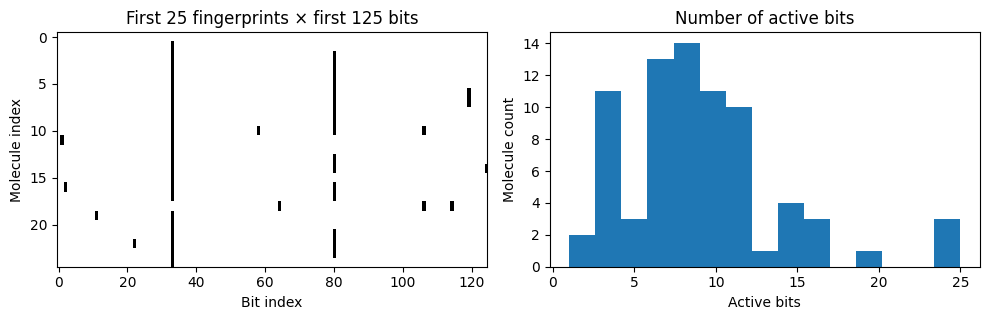

In [ ]:
# A circular Morgan fingerprint enumerates local atom neighborhoods and hashes them into fixed-length bits.
# radius=2 corresponds to the common ECFP4 convention (diameter 4).
FP_SIZE=1024
fp_gen=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=FP_SIZE)
smiles=raw.smiles.tolist()
mols=[Chem.MolFromSmiles(s) for s in smiles]
X=np.stack([fp_gen.GetFingerprintAsNumPy(m).astype(np.float32) for m in mols])
print('Feature matrix (molecules x bits):',X.shape)
print('First molecule active bits:',int(X[0].sum()))
print('First 24 bits:',X[0,:24].astype(int))
assert X.shape==(len(raw),FP_SIZE) and np.isin(X,[0,1]).all()
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
axes[0].imshow(X[:25,:125],aspect='auto',interpolation='nearest',cmap='Greys');axes[0].set(title='First 25 fingerprints × first 125 bits',xlabel='Bit index',ylabel='Molecule index')
axes[1].hist(X.sum(axis=1),bins=15);axes[1].set(title='Number of active bits',xlabel='Active bits',ylabel='Molecule count');plt.tight_layout();plt.show()

## Part 4 — Similarity and Tanimoto coefficient
For two binary fingerprints, let $a$ and $b$ be their numbers of active bits and let $c$ be the overlap. The **Tanimoto similarity** is $T=c/(a+b-c)$. For `[1,1,0,0]` and `[1,0,1,0]`, $a=b=2$, $c=1$, and $T=1/3$.

**Student task 2 (15 pts):** Compute the Tanimoto coefficient for the first two molecules by hand from counts and verify in Python; find the three most similar pairs. Discuss why high similarity does not guarantee equal biological activity.

In [ ]:
# TODO (student): calculate Tanimoto similarity for pairs of molecules.
# Hint: fp_gen.GetFingerprint(m), DataStructs.TanimotoSimilarity(fp1,fp2)
fp0,fp1=fp_gen.GetFingerprint(mols[0]),fp_gen.GetFingerprint(mols[1])
print('First pair:',DataStructs.TanimotoSimilarity(fp0,fp1))
# Add pairwise search and your interpretation below.

First pair: 0.0


## Part 5 — Labels, tasks, and masks
A **target** is an outcome to predict. Here two *illustrative proxy tasks* are computed from descriptors, not measured toxicity. A multitask matrix $y\in\mathbb{R}^{N\times T}$ has one column per task. A companion mask $w$ is 1 if a label is available and 0 otherwise.

The original tutorial uses **Tox21**, with 12 assays; some compounds were not tested in every assay. Missing is not equivalent to “inactive.”

**Student task 3 (15 pts):** Print the shape of $X$, $y$, and $w$; count missing labels. Explain why replacing missing entries with 0 would bias the model.

In [ ]:
# In multitask data, one row may have some measured labels and other missing labels.
tasks=['demo_task_lipophilic','demo_task_hbond']
y=raw[tasks].to_numpy(dtype=float)
w=np.isfinite(y).astype(float)           # 1 = present, 0 = missing
print('y shape:',y.shape,'mask shape:',w.shape)
print('Missing labels per task:',dict(zip(tasks,(w==0).sum(axis=0))))
# A missing label is NOT a negative outcome! Mask it during scoring or training.
assert y.shape==w.shape
idx_train,idx_test=train_test_split(np.arange(len(raw)),test_size=.25,random_state=SEED,shuffle=True)
idx_fit,idx_valid=train_test_split(idx_train,test_size=.25,random_state=SEED,shuffle=True)
print('Train/valid/test:',len(idx_fit),len(idx_valid),len(idx_test))

y shape: (76, 2) mask shape: (76, 2)
Missing labels per task: {'demo_task_lipophilic': np.int64(0), 'demo_task_hbond': np.int64(11)}
Train/valid/test: 42 15 19


## Part 6 — From neuron to classifier
A neuron multiplies each feature by a learned weight, sums them, adds a **bias**, and applies an activation: $z=\sum_jw_jx_j+b$, $a=\max(0,z)$ for ReLU. The bias allows a nonzero output when all features are zero.

**Example:** $x=(1,0)$, $w=(0.3,-0.7)$, $b=-0.1$ gives $z=0.2$ and ReLU$(z)=0.2$.

Binary classifiers output a probability $p$ between 0 and 1. A loss measures disagreement between predictions and known labels. Separate training and validation data prevent using evaluation data to fit weights.

**Student task 4 (20 pts):** Evaluate the above neuron manually, explain learning rate and overfitting, and compute masked binary cross-entropy for the numerical example in the next cell.

In [ ]:
# A masked binary cross-entropy example from first principles:
# BCE(t,p) = -t log(p) - (1-t)log(1-p). Multiply by w=0 for missing labels.
example_targets=np.array([[1.,np.nan],[0.,1.]])
example_weights=np.isfinite(example_targets).astype(float)
example_probs=np.array([[0.8,0.1],[0.3,0.6]])
t=np.nan_to_num(example_targets,nan=0.0)
eps=1e-10
per_entry=-(t*np.log(example_probs+eps)+(1-t)*np.log(1-example_probs+eps))
masked_loss=(per_entry*example_weights).sum()/example_weights.sum()
print('Per-entry loss:\n',per_entry.round(4))
print('Mask:\n',example_weights)
print('Masked BCE:',round(masked_loss,5))
print('Check by hand: (-log(.8)-log(.7)-log(.6))/3 =',round((-np.log(.8)-np.log(.7)-np.log(.6))/3,5))

Per-entry loss:
 [[0.2231 0.1054]
 [0.3567 0.5108]]
Mask:
 [[1. 0.]
 [1. 1.]]
Masked BCE: 0.36355
Check by hand: (-log(.8)-log(.7)-log(.6))/3 = 0.36355


## Part 7 — Training, test metrics, and scientific evaluation
A **majority baseline** predicts only the most common class; logistic regression gives a simple linear-in-fingerprint benchmark; a neural network can represent nonlinear interactions. **Accuracy** depends on a 0.5 threshold. **ROC–AUC** measures ranking ability across thresholds and is undefined if the evaluated set contains only one class. With a small sample, any metric may be unstable.

**Important:** This code is a teaching comparison of *separately fitted* task classifiers, not yet a shared multitask neural network. The genuine DeepChem example below demonstrates shared layers and 12 outputs.

**Student task 5 (20 pts):** Record validation and test metrics; compare three models; explain why a perfect score on descriptor-derived proxy tasks would not validate a toxicity predictor.

In [ ]:
# Baseline and a small neural-network classifier, fitted separately for each outcome.
# Each task uses only rows where its label is known. This is a transparent first step
# toward multitask learning; the true shared-representation example appears below.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
results=[]
models={}
for j,task in enumerate(tasks):
    fit=idx_fit[w[idx_fit,j]==1]; valid=idx_valid[w[idx_valid,j]==1]; test=idx_test[w[idx_test,j]==1]
    if len(np.unique(y[fit,j]))<2:
        print('Not enough classes for',task);continue
    baseline=DummyClassifier(strategy='prior').fit(X[fit],y[fit,j].astype(int))
    ridge=LogisticRegression(C=1.0,max_iter=1000,random_state=SEED).fit(X[fit],y[fit,j].astype(int))
    nn=MLPClassifier(hidden_layer_sizes=(24,),activation='relu',solver='adam',max_iter=220,random_state=SEED,early_stopping=False).fit(X[fit],y[fit,j].astype(int))
    models[task]=nn
    for name,model in [('Majority baseline',baseline),('Logistic regression',ridge),('Neural network',nn)]:
        for split_name,idx in [('validation',valid),('test',test)]:
            yy=y[idx,j].astype(int)
            pred=model.predict(X[idx])
            prob=model.predict_proba(X[idx])[:,1]
            auc=roc_auc_score(yy,prob) if len(np.unique(yy))==2 else np.nan
            results.append(dict(task=task,model=name,split=split_name,n=len(idx),accuracy=accuracy_score(yy,pred),roc_auc=auc))
res=pd.DataFrame(results)
print(res.round(3).to_string(index=False))
print('NOTE: tiny illustrative dataset; test scores can be noisy, and proxy targets are derived from descriptors.')

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (220) reached and the optimization hasn't converged yet.
  warnings.warn(


                task               model      split  n  accuracy  roc_auc
demo_task_lipophilic   Majority baseline validation 15     0.800    0.500
demo_task_lipophilic   Majority baseline       test 19     0.789    0.500
demo_task_lipophilic Logistic regression validation 15     0.933    0.972
demo_task_lipophilic Logistic regression       test 19     0.789    0.817
demo_task_lipophilic      Neural network validation 15     0.867    0.917
demo_task_lipophilic      Neural network       test 19     0.789    0.733
     demo_task_hbond   Majority baseline validation 14     0.857    0.500
     demo_task_hbond   Majority baseline       test 16     0.875    0.500
     demo_task_hbond Logistic regression validation 14     0.929    1.000
     demo_task_hbond Logistic regression       test 16     0.875    0.893
     demo_task_hbond      Neural network validation 14     0.929    1.000
     demo_task_hbond      Neural network       test 16     0.875    0.821
NOTE: tiny illustrative dataset; test 

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (220) reached and the optimization hasn't converged yet.
  warnings.warn(


## Part 8 — ROC curves
A ROC curve plots **true positive rate** against **false positive rate** as the decision threshold changes.

**Student task 6 (15 pts):** Plot ROC curves for a task having two classes in the test subset; label the axes and AUC. Interpret a result near 0.5 and a result near 1.0.

In [ ]:
# TODO (student): choose one task with both classes in its test subset.
# Use sklearn.metrics.roc_curve() and roc_auc_score() to create a labeled ROC plot.
print('Available fitted tasks:',list(models))

Available fitted tasks: ['demo_task_lipophilic', 'demo_task_hbond']


## Part 9 — Original Tox21 workflow (optional extension)
The source tutorial loads Tox21 using `dc.molnet.load_tox21(featurizer='ECFP')`, yielding a 1,024-feature fingerprint matrix and 12 toxicity tasks, and trains a shared `MultitaskClassifier` with one 1,000-neuron hidden layer. The weights matrix marks missing assay labels, and ROC–AUC is used for evaluation.

DeepChem dependencies, internet access, and runtime can vary, so this optional section is not needed for the introductory assignment. For realistic chemical evaluation, consider a **scaffold split**: closely related structural families should not appear in both training and test partitions.

**Student task 7 (optional +5 bonus pts):** Run the Tox21 experiment and compare the validation and test ROC–AUC, explaining possible distribution shift and missing labels.

In [ ]:
# OPTIONAL ADVANCED ACTIVITY: genuine Tox21 (12 measured assay endpoints)
# Requires network access and DeepChem installation in Colab.
# This is not required for the introductory CSV exercise.
# Uncomment and run only if instructed by the teacher:
# %pip -q install deepchem
# import deepchem as dc
# tasks_tox, datasets_tox, transformers_tox = dc.molnet.load_tox21(featurizer='ECFP', splitter='scaffold')
# train_tox, val_tox, test_tox = datasets_tox
# print('Tasks:',tasks_tox)
# print('Training X/y/w:',train_tox.X.shape,train_tox.y.shape,train_tox.w.shape)
# model_tox=dc.models.MultitaskClassifier(n_tasks=len(tasks_tox),n_features=train_tox.X.shape[1],layer_sizes=[1000])
# model_tox.fit(train_tox,nb_epoch=10)
# metric=dc.metrics.Metric(dc.metrics.roc_auc_score)
# print('VALIDATION:',model_tox.evaluate(val_tox,[metric],transformers_tox))
# print('TEST:',model_tox.evaluate(test_tox,[metric],transformers_tox))
# Dataset provenance and splitting differ from the small demonstration CSV.


## Homework checklist and grading
Submit one executed notebook with numbered answers, annotated plots, and a final 150–250-word scientific interpretation. Include a sentence distinguishing proxy labels from experimental toxicity labels.

| Task | Points |
|---|---:|
| 1. Fingerprints and molecular structures | 15 |
| 2. Tanimoto calculations and similarities | 15 |
| 3. Multitask labels and missing masks | 15 |
| 4. Neuron mathematics and masked loss | 20 |
| 5. Model comparison and limitations | 20 |
| 6. ROC visualization and interpretation | 15 |
| **Total** | **100** |

**Assessment:** complete requested outputs, clear mathematical work, correct interpretation, and reproducibility. The optional Tox21 extension is extra credit, not required.